#Paper reference simulation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from utilities import make_grid, angular_spectrum, plot_field, pupil
from ilumination import source_field, source_spectrum, mirror_pupil

###Illumination

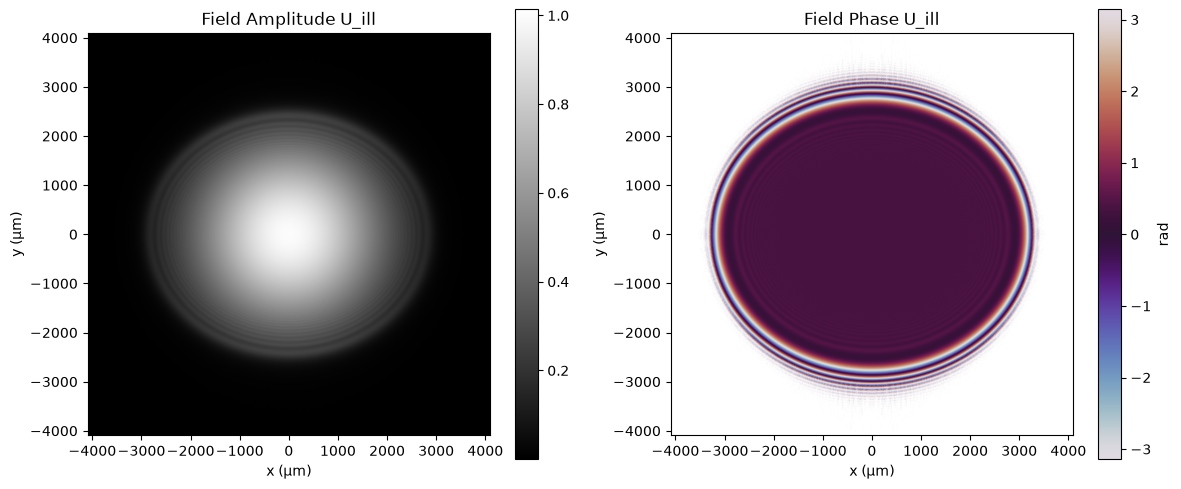

In [2]:
central_lam = 0.850 # central wavelength in micrometers
fwhm = 0.06  # full width at half maximum in micrometers
n = np.array([4096, 4096])
dx, dy = 2, 2
w0 = 2e3

X, Y = make_grid(n, dx, dy)
U_source = source_field(X, Y, central_lam, w0)
S_source = source_spectrum(central_lam, fwhm, n_k=33)

z_M1 = 50e3  # distance to mirror in micrometers

U_M1_ = angular_spectrum(U_source, dx=dx, dy=dy, z=z_M1, lam=central_lam)

M1_r = 3e3 # Mirror 1 radius in micrometers
M1_theta = 30
P_M1 = mirror_pupil(X, Y, M1_r, M1_theta)

U_M1 = U_M1_ * P_M1

z_sample = 50e3  # distance to sample in micrometers
U_sample = angular_spectrum(U_M1, dx=dx, dy=dy, z=z_sample, lam=central_lam)

plot_field(U_sample, X, Y, "U_ill")

##Just after paper

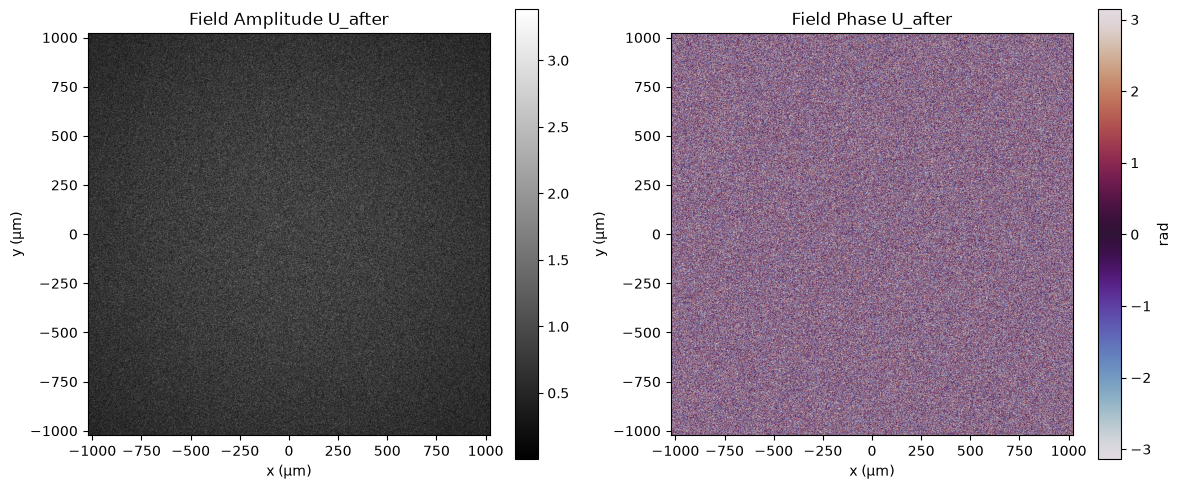

In [3]:
from doppler_scattering import paper_field

SEED_SCREEN, SEED_PAPER, SEED_CELLS = 0, 1, 2      # screen, paper camera noise, cell camera noise

s = slice(n[0]//2 - 512, n[0]//2 + 512)            # 1024 x 1024 px = 2 mm, contains the 1 mm disk
U_ill, Xc, Yc = U_sample[s, s], X[s, s], Y[s, s]

# One sheet of paper: g is drawn ONCE here and reused for every frame.
# paper_field with a unit illumination returns the normalized screen g itself.
g = paper_field(np.ones_like(U_ill), Xc, Yc, rng=np.random.default_rng(SEED_SCREEN))
U_after = U_ill * g                                # identical to paper_field(U_ill, ...) with the same rng

plot_field(U_after, Xc, Yc, "U_after")

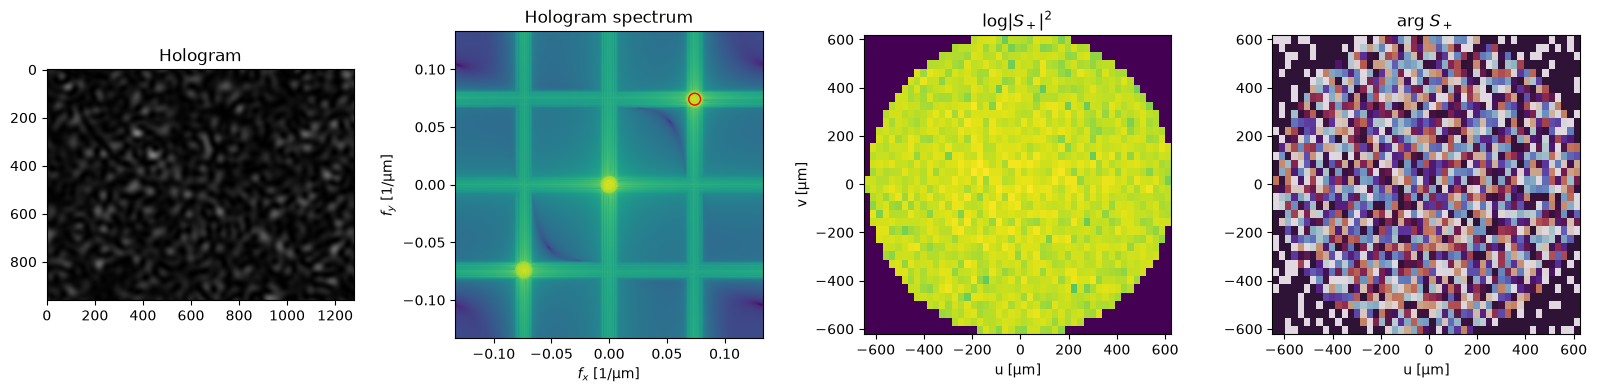

sideband pixels: 1406


In [4]:
from collection import lens_transmitance, camera_hologram, sideband
from utilities import fresnel_fft
from matplotlib.patches import Circle

f1, R1 = 75e3, 12.7e3          # objective focal length and radius (1-inch lens assumed)
R_IP = 500                     # field stop at the image plane
f2 = 150e3
theta = 0.51 * np.radians(5)   # (n_g - 1) * beta, with apex 169° (5.5°)
d_B = 140e3
p = 3.75
xc = (np.arange(1280) - 640) * p
yc = (np.arange(960) - 480) * p
Lambda = central_lam / (2 * theta)
r_sb = 1.3 * R_IP / (central_lam * f2)

def hologram(U_after):
    """Objective (2f1, lens, 2f1), field stop and biprism camera: the chain of per_surface_analysis."""
    U_L1, X1, Y1 = fresnel_fft(U_after, Xc, Yc, central_lam, 2*f1)
    U_L1 = U_L1 * lens_transmitance(X1, Y1, f1, central_lam, R1)
    U_IP, Xi, Yi = fresnel_fft(U_L1, X1, Y1, central_lam, 2*f1)
    return camera_hologram(U_IP * pupil(Xi, Yi, R_IP), Xi, Yi, central_lam, f2, xc, yc, theta, d_B)

I_paper = hologram(U_after)    # static paper + linear optics -> the same I in every frame
I = I_paper

# Save the hologram (own name, so the cell notebook's hologram.png is not overwritten)
plt.imsave('hologram_paper.png', I, cmap='gray')

# Spectrum of the hologram and its frequency axes [1/µm]
F = np.fft.fftshift(np.fft.fft2(I - I.mean()))
fx = np.fft.fftshift(np.fft.fftfreq(I.shape[1], p))
fy = np.fft.fftshift(np.fft.fftfreq(I.shape[0], p))

# Carrier along the biprism normal
c = np.array([np.cos(np.radians(45)), np.sin(np.radians(45))]) / Lambda

# Crop a box around the carrier, then mask it to a disk
ix = np.abs(fx - c[0]) <= r_sb
iy = np.abs(fy - c[1]) <= r_sb
FX, FY = np.meshgrid(fx[ix], fy[iy])
F_sb = F[np.ix_(iy, ix)] * (np.hypot(FX - c[0], FY - c[1]) <= r_sb)

# Fourier-plane coordinates mapped back to image-plane µm: u = λ f2 (f - c)
ext = central_lam * f2 * np.array([fx[ix][0] - c[0], fx[ix][-1] - c[0],
                                   fy[iy][0] - c[1], fy[iy][-1] - c[1]])

plt.figure(figsize=(16, 4.5))
plt.subplot(1, 4, 1); plt.imshow(I, cmap='gray'); plt.title('Hologram')
ax = plt.subplot(1, 4, 2)
plt.imshow(np.log10(np.abs(F)**2 + 1e-12), origin='lower',
           extent=[fx[0], fx[-1], fy[0], fy[-1]])
ax.add_patch(Circle(c, r_sb, fill=False, color='r'))
plt.xlabel(r'$f_x$ [1/µm]'); plt.ylabel(r'$f_y$ [1/µm]'); plt.title('Hologram spectrum')
plt.subplot(1, 4, 3)
plt.imshow(np.log10(np.abs(F_sb)**2 + 1e-12), origin='lower', extent=ext)
plt.xlabel('u [µm]'); plt.ylabel('v [µm]'); plt.title(r'$\log|S_+|^2$')
plt.subplot(1, 4, 4)
plt.imshow(np.angle(F_sb), cmap='twilight', origin='lower', extent=ext)
plt.xlabel('u [µm]'); plt.title(r'arg $S_+$')
plt.tight_layout(); plt.show()
print(f'sideband pixels: {np.count_nonzero(F_sb)}')

In [6]:
from spectrum import field_spectrum, log_bin, knee_frequency
from tqdm.auto import tqdm

n_frames, fs = 1400, 0.2
full_well, read = 1e4, 5.0

def exposure(I):
    """Electrons per intensity unit: the 99.9th percentile pixel fills the well."""
    return full_well / np.percentile(I, 99.9)

def camera_frame(I, scale, rng):
    """One noisy frame in electrons: shot noise + read noise, then saturation."""
    e = rng.poisson(I * scale) + read * rng.standard_normal(I.shape)
    return np.clip(e, 0, full_well)

# Noiseless check: S+ is constant, so its spectrum is zero to numerical precision
S0 = sideband(I_paper, p, Lambda, radius=r_sb)
n_sb = S0.size
_, P0 = field_spectrum(np.tile(S0, (n_frames, 1)), fps=fs)
print(f'sideband pixels: {n_sb}')
print(f'noiseless paper: max P / <|S+|^2> = {P0.max() / np.mean(np.abs(S0)**2):.1e}')

# Paper run: I is fixed, only the camera noise changes from frame to frame
scale_paper = exposure(I_paper)
S_paper = np.empty((n_frames, n_sb), dtype=complex)
for k in tqdm(range(n_frames), desc='Paper frames'):
    rng = np.random.default_rng([SEED_PAPER, k])     # per-frame seed: reproducible
    S_paper[k] = sideband(camera_frame(I_paper, scale_paper, rng), p, Lambda, radius=r_sb)
np.save('S_paper_noisy.npy', S_paper)

c:\Users\andre\iCloudDrive\Uni\Semestre 7\Avanzado\Simulation_BioTissue_FBDHS\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


sideband pixels: 1406
noiseless paper: max P / <|S+|^2> = 8.6e-25


Paper frames: 100%|██████████| 1400/1400 [03:24<00:00,  6.84it/s]


Ne = 1422.6 e-,  N_pix = 1228800
formula   P_floor = 1.7789e+10
measured  mean(P) = 1.7640e+10   ratio 0.9916
scatter std/mean  = 0.022   1/sqrt(n_sb) = 0.027
lowest bin/floor  = 0.814   expected (5/16)/(3/8) = 0.833 (mean-removal artifact)


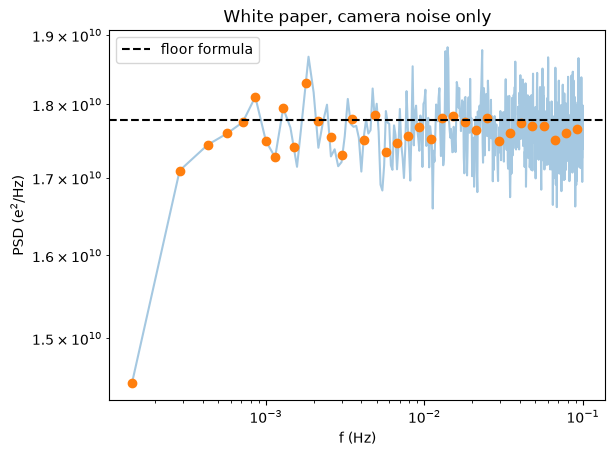

In [14]:
# Floor check (no knee fit: the paper spectrum is white noise)
S_paper = np.load('S_paper_noisy.npy')
f, P_paper = field_spectrum(S_paper, fps=fs)

Ne = (I_paper * scale_paper).mean()
N_pix = I_paper.size
P_floor = 2 * N_pix * (Ne + read**2) / fs

print(f'Ne = {Ne:.1f} e-,  N_pix = {N_pix}')
print(f'formula   P_floor = {P_floor:.4e}')
print(f'measured  mean(P) = {P_paper.mean():.4e}   ratio {P_paper.mean() / P_floor:.4f}')
print(f'scatter std/mean  = {P_paper.std() / P_paper.mean():.3f}   1/sqrt(n_sb) = {1/np.sqrt(n_sb):.3f}')
print(f'lowest bin/floor  = {P_paper[0] / P_floor:.3f}   expected (5/16)/(3/8) = {5/6:.3f} (mean-removal artifact)')

plt.loglog(f, P_paper, alpha=0.4)
plt.loglog(*log_bin(f, P_paper), 'o')
plt.axhline(P_floor, color='k', ls='--', label='floor formula')
plt.xlabel('f (Hz)'); plt.ylabel('PSD (e$^2$/Hz)'); plt.title('White paper, camera noise only')
plt.legend(); plt.show()

In [11]:
# Cell run: same chain as per_surface_analysis, clean and noisy S+ from the same hologram
from pathlib import Path
from doppler_scattering import scattering_vector, mie_amplitude, object_amplitudes, field_after_sample

DPD = Path.cwd().parents[1] / "DPD tissue" / "code"
trajs = [dict(np.load(DPD / "runs" / f"cell_{k}" / "traj.npz")) for k in range(4)]
layout = dict(np.load(DPD / "layout.npz"))

q, theta_s = scattering_vector()
q2 = np.sum(q**2)
print(f'|q| = {np.sqrt(q2):.2f} µm⁻¹')              # ≈ 19.30

S_name = {"nucleus": mie_amplitude(1.0, 1.39, 1.36, theta_s),
          "mitochondrion": mie_amplitude(0.44, 1.41, 1.36, theta_s),
          "vesicle": mie_amplitude(0.25, 1.40, 1.36, theta_s)}
amps = object_amplitudes(layout, trajs, S_name)

# Checkpoint every 100 frames; delete the file if any optical parameter changes
ckpt = Path('S_cells_checkpoint.npz')
S_cells_clean = np.empty((n_frames, n_sb), dtype=complex)
S_cells_noisy = np.empty_like(S_cells_clean)
start = 0
if ckpt.exists():                                  # resume an interrupted run
    ck = np.load(ckpt)
    start = int(ck['done'])
    S_cells_clean[:start], S_cells_noisy[:start] = ck['clean'], ck['noisy']
    scale_cells = float(ck['scale'])
    print(f'resuming at frame {start}')

for k in tqdm(range(start, n_frames), initial=start, total=n_frames, desc='Cell frames'):
    I_k = hologram(field_after_sample(k, U_ill, Xc, Yc, layout, trajs, amps, q))
    if k == 0:
        scale_cells = exposure(I_k)                # set on frame 0, never rescaled
    rng = np.random.default_rng([SEED_CELLS, k])
    S_cells_clean[k] = sideband(I_k, p, Lambda, radius=r_sb)
    S_cells_noisy[k] = sideband(camera_frame(I_k, scale_cells, rng), p, Lambda, radius=r_sb)

    if (k + 1) % 100 == 0:
        np.savez(ckpt, clean=S_cells_clean[:k+1], noisy=S_cells_noisy[:k+1],
                 scale=scale_cells, done=k+1)

np.save('S_cells_clean.npy', S_cells_clean)
np.save('S_cells_noisy.npy', S_cells_noisy)

|q| = 19.30 µm⁻¹
resuming at frame 1400


Cell frames: 100%|██████████| 1400/1400 [00:00<?, ?it/s]


In [12]:
# Knee checks: noisy vs clean cells (both should be ≈ 6.11 mHz)
S_cells_clean = np.load('S_cells_clean.npy')
S_cells_noisy = np.load('S_cells_noisy.npy')
f, P_cells_clean = field_spectrum(S_cells_clean, fps=fs)
_, P_cells_noisy = field_spectrum(S_cells_noisy, fps=fs)

fk_clean = knee_frequency(f, P_cells_clean, fps=fs)
fk_noisy = knee_frequency(f, P_cells_noisy, fps=fs)
for name, fk in [('clean', fk_clean), ('noisy', fk_noisy)]:
    print(f'cells {name}: knee {fk*1e3:.2f} mHz  ->  D = {np.pi * fk / q2:.3e} µm²/s')

cells clean: knee 6.11 mHz  ->  D = 5.156e-05 µm²/s
cells noisy: knee 6.11 mHz  ->  D = 5.156e-05 µm²/s


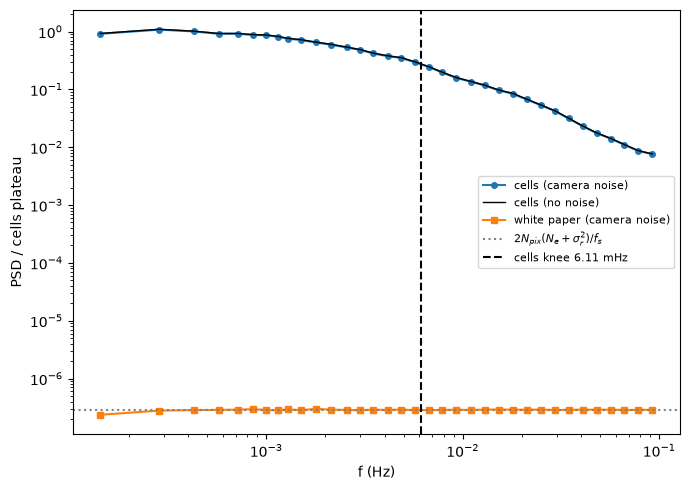

paper floor below cells plateau : 6.54 decades
paper below cells at Nyquist    : 4.42 decades (f = 0.092 Hz)
noisy/clean cells at Nyquist    : 0.9884  (≈ 1 + floor/clean)


In [16]:
# Figure: cells vs paper, both through the same camera (PSD in e^2), normalized to the cells plateau
# The clean S+ comes from I in simulation units; sideband is linear, so its PSD scales with scale_cells^2
if 'scale_cells' not in globals():
    scale_cells = float(np.load('S_cells_checkpoint.npz')['scale'])

fb, Pb_cells = log_bin(f, P_cells_noisy)
_, Pb_clean = log_bin(f, P_cells_clean * scale_cells**2)   # clean cells in e^2, same units as the noisy ones
_, Pb_paper = log_bin(f, P_paper)
plateau = Pb_cells[:3].mean()                      # mean of the first 3 log bins of the cells

fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(fb, Pb_cells / plateau, 'o-', ms=4, label='cells (camera noise)')
ax.loglog(fb, Pb_clean / plateau, '-', color='k', lw=1, label='cells (no noise)')
ax.loglog(fb, Pb_paper / plateau, 's-', ms=4, color='C1', label='white paper (camera noise)')
ax.axhline(P_floor / plateau, color='gray', ls=':', label=r'$2N_{pix}(N_e+\sigma_r^2)/f_s$')
ax.axvline(fk_noisy, color='k', ls='--', label=f'cells knee {fk_noisy*1e3:.2f} mHz')
ax.set(xlabel='f (Hz)', ylabel='PSD / cells plateau')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig('../graphs/paper_vs_cells.png', dpi=200)
plt.show()

print(f'paper floor below cells plateau : {np.log10(plateau / Pb_paper.mean()):.2f} decades')
print(f'paper below cells at Nyquist    : {np.log10(Pb_cells[-1] / Pb_paper[-1]):.2f} decades '
      f'(f = {fb[-1]:.3f} Hz)')
print(f'noisy/clean cells at Nyquist    : {Pb_cells[-1] / Pb_clean[-1]:.4f}  (≈ 1 + floor/clean)')

In [ ]:
# Optional validation: paper that decorrelates at a known rate (full optics per frame, about 25 min)
RUN_DECORR = False
tau_c = 60.0                                       # s  ->  expected knee 1/(pi tau_c) ≈ 5.3 mHz

if RUN_DECORR:
    dt = 1 / fs
    rho = np.exp(-dt / tau_c)                      # rho = 0 is a new sheet every frame (white noise)
    rng_d = np.random.default_rng(SEED_SCREEN + 10)
    ones = np.ones_like(U_ill)
    g_t = paper_field(ones, Xc, Yc, rng=rng_d)     # unit-variance circular Gaussian screen

    S_dec = np.empty((n_frames, n_sb), dtype=complex)
    for k in tqdm(range(n_frames), desc='Decorrelating paper'):
        S_dec[k] = sideband(hologram(U_ill * g_t), p, Lambda, radius=r_sb)
        w = paper_field(ones, Xc, Yc, rng=rng_d)   # fresh complex white noise, unit variance
        g_t = rho * g_t + np.sqrt(1 - rho**2) * w  # AR(1): keeps the variance, correlation rho per frame
    np.save('S_paper_decorr.npy', S_dec)

    f, P_dec = field_spectrum(S_dec, fps=fs)
    fk_dec = knee_frequency(f, P_dec, fps=fs)
    print(f'decorrelating paper: knee {fk_dec*1e3:.2f} mHz, expected 1/(pi tau_c) = {1e3/(np.pi*tau_c):.2f} mHz')

    plt.loglog(f, P_dec, alpha=0.4)
    plt.loglog(*log_bin(f, P_dec), 'o')
    plt.axvline(fk_dec, ls='--', label='fit')
    plt.axvline(1 / (np.pi * tau_c), color='k', ls=':', label=r'$1/(\pi\tau_c)$')
    plt.xlabel('f (Hz)'); plt.ylabel('PSD'); plt.legend(); plt.show()